<a href="https://colab.research.google.com/github/simichakravarty16/walmart-hurricane-project/blob/main/notebooks/scratch/2026-10-28%20%E2%80%94%20Midterm%20Clinic%20Analysis%20and%20Charts%20%E2%80%94%20Studio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Clinic Analysis and Charts

**Studio — 2026-10-28 · Fall 2026**  
**Class time:** 45 minutes

---

## Clinic — analysis and charts

Working session on your own project. The patterns below are the four analytical moves Questions 1 through 4 need; adapt each one to your cleaned data.

By the end of the hour you should have at least two charts you would be willing to put in the presentation on Monday.

In [1]:
import pandas as pd
import os
import sqlite3
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests, time

In [2]:
DECISIONS = []

def log(dataset, step, decision, rows_affected):
    DECISIONS.append({'dataset': dataset, 'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{dataset}] [{step}] {decision} ({rows_affected} row(s))')

In [3]:
# Set data directory
DATA_DIR = '/content'

# Define data loading function
def load_data(filename):
  return pd.read_csv(os.path.join(DATA_DIR, filename))

In [4]:
# Load walmart transactions dataset
transactions = load_data('walmart_transactions.csv')
transactions.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


In [5]:
# Transform: Types and Duplicates
def transform_types(df):
    out = df.copy()

    # Drop duplicates
    before = len(out)
    out = out.drop_duplicates()
    removed = before - len(out)
    log('walmart_transactions', 'remove duplicates', 'Removed duplicate rows', removed)

    # Normalize timestamps
    out['timestamp'] = pd.to_datetime(out['timestamp'], errors='coerce', format='mixed')
    missing = out['timestamp'].isna().sum()
    log('walmart_transactions', 'clean timestamp', 'Converted timestamps to datetime and kept missing values as NaT', missing)

    # Create date column for joining with daily weather data
    out['date'] = out['timestamp'].dt.normalize()
    log('walmart_transactions', 'create date column', 'Extracted calendar date from timestamp for weather merge', out['date'].notna().sum())

    # Convert unit_price to float (no $ sign)
    out['unit_price'] = (out['unit_price'].astype(str)
                         .str.replace('$', '', regex=False) # remove $ sign
                         .str.strip().astype(float))    # change unit prices to float
    affected_price = len(out)
    log('walmart_transactions', 'clean unit_price', 'Removed $ sign and converted unit_price to float', affected_price)

    # Clean quantity
    before = len(out)
    out['quantity'] = pd.to_numeric(out['quantity'], errors='coerce')
    # Decision: drop the unparseable quantity and the return. We are measuring
    # units that left the shelf ahead of the hurricane, so a return is not that.
    out = out[out['quantity'].notna() & (out['quantity'] > 0)].copy()
    out['quantity'] = out['quantity'].astype(int)
    removed_quantity = before - len(out)
    log('walmart_transactions', 'clean quantity', 'Removed negative quantities (returns)', removed_quantity)

    # Standardize store_id
    old_id = out['store_id'].copy()
    out['store_id'] = out['store_id'].astype(str).str.upper().str.strip().str.replace(r'^FL[\s_-]*(\d+)$', r'FL-\1', regex=True)
    affected_id = (old_id != out['store_id']).sum()
    log('walmart_transactions', 'clean store_id', 'Standardized store IDs to FL-# format', affected_id)

    return out

In [6]:
# Transform: consolidate SKUs, product names, and categories

# Consolidate SKUs
SKU_MAP = {
    'BATT_AA_4PK': 'BAT-AA4',
    'BATT-100': 'BAT-AA4',
    'BEER-24': 'LTBEER24',
    'BABYFORMULA': 'BFORM-01',
    'BG-MONO': 'BG-MONO-01',
    'MONOPOLY-01': 'BG-MONO-01',
    'GAME-MONO': 'BG-MONO-01',
    'BREAD-WH': 'WHITEBREAD',
    'CNDL-EM': 'CANDLE-EMRG',
    'PLAYCARD-STD': 'CARDS-01',
    'CHIPVARIETY': 'CHIPS-VP',
    'PORTCHARGER': 'CHRG-PORT',
    'SOUP-CAN': 'CNSOUP-01',
    'DIAPERS-3': 'DIAP-S3',
    'FIRSTAID-KIT': 'FAID-01',
    'LED-FLASH': 'FLASH-01',
    'TARP-HD': 'HDTARP-01',
    'PAPERTOWEL6': 'PTOWEL6',
    'PTOWEL-6': 'PTOWEL6',
    'TOILETPAPER12': 'TOILETPAPER-12',
    'TP-12': 'TOILETPAPER-12',
    'PB-16': 'PNUTBTR-16',
    'PT-12': 'POPTART-STRAW',
    'SKU#459812': 'POPTART-STRAW',
    'PT_STRAWBERRY': 'POPTART-STRAW',
    'ROKU-STD': 'ROKU-STREAM',
    'STREAM-01': 'ROKU-STREAM',
    'WATER24PK': 'WATER-24',
    'WTR_24PK': 'WATER-24',
    'WTR-24': 'WATER-24'
}

# Standardize product names
PRODUCT_MAP = {
    'BAT-AA4': 'Batteries AA 4PK',
    'LTBEER24': 'Light Beer 24PK',
    'BFORM-01': 'Baby Formula',
    'BG-MONO-01': 'Monopoly Board Game',
    'WHITEBREAD': 'White Bread',
    'CANDLE-EMRG': 'Emergency Candle',
    'CARDS-01': 'Playing Cards',
    'CHIPS-VP': 'Chip Variety Pack',
    'CHRG-PORT': 'Portable Phone Charger',
    'CNSOUP-01': 'Canned Soup',
    'DIAP-S3': 'Diapers Size 3',
    'FAID-01': 'First Aid Kit',
    'FLASH-01': 'LED Flashlight',
    'HDTARP-01': 'Heavy Duty Tarp',
    'PTOWEL6': 'Paper Towels 6PK',
    'TOILETPAPER-12': 'Toilet Paper 12PK',
    'PNUTBTR-16': 'Peanut Butter 16oz',
    'POPTART-STRAW': 'Pop-Tarts Strawberry',
    'ROKU-STREAM': 'Roku Streaming Stick',
    'WATER-24': 'Bottled Water 24PK'
}

# Standardize categories
CATEGORY_MAP = {
    'Alcoholic Beverages': 'Alcohol',
    'Baby Products': 'Baby',
    'Breakfast Foods': 'Breakfast',
    'Emergency Supplies': 'Emergency',
    'Groceries': 'Grocery',
    'Games & Entertainment': 'Entertainment',
    'Health & Wellness': 'Health',
    'Household Essentials': 'Household'
}

def consolidate_transactions(df):
    out = df.copy()

    # Consolidate SKUs
    old_sku = out['sku'].copy()
    out['sku'] = out['sku'].map(SKU_MAP).fillna(out['sku'])
    affected_sku = (old_sku != out['sku']).sum()
    log('walmart_transactions', 'clean sku', 'Consolidated SKUs so the same products share the same SKU', affected_sku)

    # Standardize product names
    old_name = out['product_name'].copy()
    out['product_name'] = out['sku'].map(PRODUCT_MAP).fillna(out['product_name'])
    affected_name = (old_name != out['product_name']).sum()
    log('walmart_transactions', 'clean product_name', 'Standardized product names based on SKUs for consistency', affected_name)

    # Standardize categories
    old_category = out['category'].copy()
    out['category'] = out['category'].str.strip().str.title().replace(CATEGORY_MAP)
    affected_category = (old_category != out['category']).sum()
    log('walmart_transactions', 'clean category', 'Standardized category names, capitalization, and spacing', affected_category)

    return out

In [7]:
def clean_walmart_transactions(df):
    df = transform_types(df)
    df = consolidate_transactions(df)
    return df

clean_transactions = clean_walmart_transactions(transactions)
display(clean_transactions.head())

print('Shape:', clean_transactions.shape)
print('\nData Types:')
print(clean_transactions.dtypes)
print()

# Check number of rows before and after cleaning
print('Rows before cleaning:', len(transactions))
print('Rows after cleaning:', len(clean_transactions))
print('Rows removed:', len(transactions) - len(clean_transactions))
print()

# Validate consolidation
print('unique SKUs after:', clean_transactions['sku'].nunique())
print('unique product names after:', clean_transactions['product_name'].nunique())
print('unique categories after:', clean_transactions['category'].nunique())

[walmart_transactions] [remove duplicates] Removed duplicate rows (30 row(s))
[walmart_transactions] [clean timestamp] Converted timestamps to datetime and kept missing values as NaT (884 row(s))
[walmart_transactions] [create date column] Extracted calendar date from timestamp for weather merge (24648 row(s))
[walmart_transactions] [clean unit_price] Removed $ sign and converted unit_price to float (25532 row(s))
[walmart_transactions] [clean quantity] Removed negative quantities (returns) (130 row(s))
[walmart_transactions] [clean store_id] Standardized store IDs to FL-# format (4324 row(s))
[walmart_transactions] [clean sku] Consolidated SKUs so the same products share the same SKU (16702 row(s))
[walmart_transactions] [clean product_name] Standardized product names based on SKUs for consistency (20155 row(s))
[walmart_transactions] [clean category] Standardized category names, capitalization, and spacing (18649 row(s))


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,date
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,Peanut Butter 16oz,Grocery,1,3.15,2024-09-24
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,Canned Soup,Grocery,1,2.02,2024-09-13
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER-12,Toilet Paper 12PK,Household,2,10.47,2024-09-17
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STREAM,Roku Streaming Stick,Electronics,1,28.59,2024-09-11
4,TXN015797,FL-302,2024-09-26 15:59:42,LTBEER24,Light Beer 24PK,Alcohol,3,18.82,2024-09-26


Shape: (25402, 9)

Data Types:
transaction_id            object
store_id                  object
timestamp         datetime64[ns]
sku                       object
product_name              object
category                  object
quantity                   int64
unit_price               float64
date              datetime64[ns]
dtype: object

Rows before cleaning: 25562
Rows after cleaning: 25402
Rows removed: 160

unique SKUs after: 20
unique product names after: 20
unique categories after: 10


### Pattern 1 — products moving together before landfall

One line per product, landfall marked. This is the Q1 chart, and it is the one that carries your presentation.

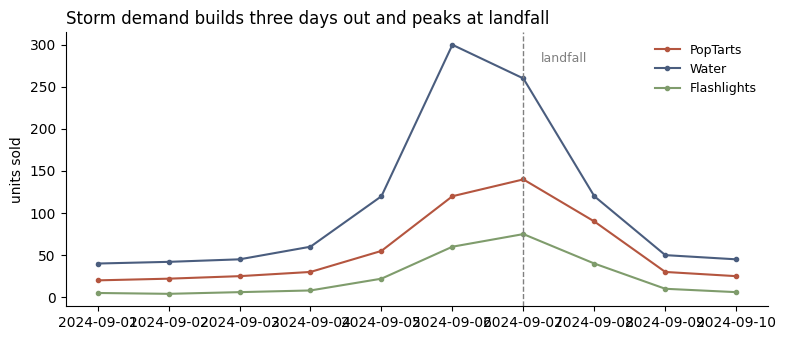

In [8]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

daily = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=10),
    'PopTarts': [20, 22, 25, 30, 55, 120, 140, 90, 30, 25],
    'Water': [40, 42, 45, 60, 120, 300, 260, 120, 50, 45],
    'Flashlights': [5, 4, 6, 8, 22, 60, 75, 40, 10, 6],
}).set_index('date')
landfall = pd.Timestamp('2024-09-07')

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(daily.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall + pd.Timedelta(hours=6), 280),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds three days out and peaks at landfall',
             loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** rebuild that with your own cleaned categories and your own landfall date. Title it with what your data actually shows — if your surge peaks a day early, say that.

In [9]:
# Q1, Step 1: Calculate daily units sold by category

# Hurricane Helene made landfall on the Florida Big Bend late on September 26, 2024
# Baseline: Sept 1-15; Surge: Sept 19-25

# Daily sales by category
daily_sales = (
    clean_transactions.dropna(subset=['date'])
    .groupby(['date', 'category'])['quantity']
    .sum()
    .reset_index(name='units_sold')
)
daily_sales.head()

,date,category,units_sold
0,2024-09-01,Alcohol,63
1,2024-09-01,Baby,88
2,2024-09-01,Breakfast,81
3,2024-09-01,Electronics,60
4,2024-09-01,Emergency,343


In [10]:
# Q1, Step 2: Define basedline and surge periods
LANDFALL = pd.Timestamp('2024-09-26')

# Baseline period: Sept 1-15
baseline = daily_sales[daily_sales['date'].between('2024-09-01', '2024-09-15')]

# Surge period: Sept 19-25
surge = daily_sales[daily_sales['date'].between('2024-09-19', '2024-09-25')]

In [11]:
# Q1, Step 3: Calculate average daily units sold

# Average daily orders during basline (15 days)
baseline_avg = baseline.groupby('category')['units_sold'].sum() / 15

# Average daily orders during surge (7 days)
surge_avg = surge.groupby('category')['units_sold'].sum()/ 7

display(baseline_avg)
display(surge_avg)

,units_sold
category,
Alcohol,61.533333
Baby,85.200000
Breakfast,73.266667
Electronics,70.266667
Emergency,354.066667
Entertainment,101.600000
Grocery,171.066667
Health,42.333333
Household,85.133333


,units_sold
category,
Alcohol,138.857143
Baby,133.714286
Breakfast,376.857143
Electronics,175.857143
Emergency,1006.428571
Entertainment,228.571429
Grocery,306.571429
Health,95.000000
Household,176.285714


In [12]:
# Q1, Step 4: Combine the averages into one DataFrame
comparision = pd.DataFrame({
    'baseline_avg': baseline_avg,
    'surge_avg': surge_avg
})

comparision['pct_change'] = (
    (comparision['surge_avg'] - comparision['baseline_avg']) /
    comparision['baseline_avg'].replace(0, float('nan')) * 100
)

comparision.round(2)

,baseline_avg,surge_avg,pct_change
category,,,
Alcohol,61.53,138.86,125.66
Baby,85.20,133.71,56.94
Breakfast,73.27,376.86,414.36
Electronics,70.27,175.86,150.27
Emergency,354.07,1006.43,184.25
Entertainment,101.60,228.57,124.97
Grocery,171.07,306.57,79.21
Health,42.33,95.00,124.41
Household,85.13,176.29,107.07


In [13]:
# Q1, Step 5: Identify the top five categories
top_5 = comparision.sort_values('pct_change', ascending=False).head(5)
top_5.round(2)

,baseline_avg,surge_avg,pct_change
category,,,
Breakfast,73.27,376.86,414.36
Emergency,354.07,1006.43,184.25
Electronics,70.27,175.86,150.27
Alcohol,61.53,138.86,125.66
Entertainment,101.60,228.57,124.97


In [14]:
# Q1, Step 6A: Prepare data for visualization

# Get the top five categories
top_5_categories = top_5.index.tolist()

# Filter the data for the top five categories
top_daily_sales = daily_sales[daily_sales['category'].isin(top_5_categories)]

top_daily_sales.head()

,date,category,units_sold
0,2024-09-01,Alcohol,63
2,2024-09-01,Breakfast,81
3,2024-09-01,Electronics,60
4,2024-09-01,Emergency,343
5,2024-09-01,Entertainment,99


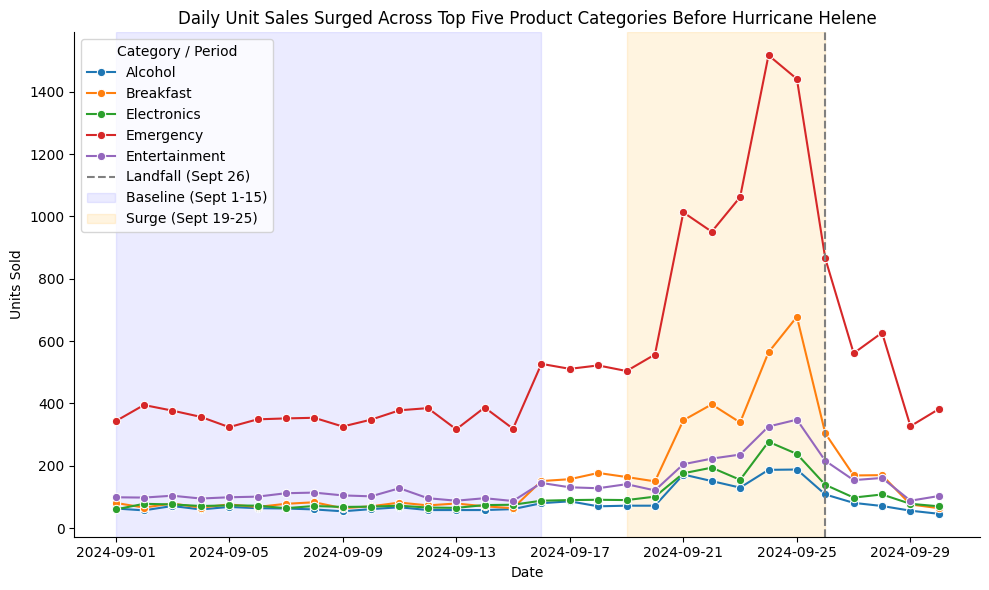

In [15]:
# Q1, Step 6B: Create line chart for absolute daily sales
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(data=top_daily_sales, x='date', y='units_sold', hue='category', marker='o',ax=ax)

# Mark hurricane landfall
ax.axvline(
    pd.Timestamp('2024-09-26'),
    color='gray',
    linestyle='--',
    label='Landfall (Sept 26)'
)

# Highlight baseline period: September 1–15
ax.axvspan(
    pd.Timestamp('2024-09-01'),
    pd.Timestamp('2024-09-16'),
    color='blue',
    alpha=0.08,
    label='Baseline (Sept 1-15)'
)

# Highlight surge period: September 19–25
ax.axvspan(
    pd.Timestamp('2024-09-19'),
    pd.Timestamp('2024-09-26'),
    color='orange',
    alpha=0.12,
    label='Surge (Sept 19-25)'
)

ax.set_title('Daily Unit Sales Surged Across Top Five Product Categories Before Hurricane Helene')
ax.set_xlabel('Date')
ax.set_ylabel('Units Sold')
ax.set_xticks(pd.date_range('2024-09-01', '2024-09-30', freq='4D'))
ax.legend(title='Category / Period')

for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

### Pattern 2 — indexing to baseline so different products are comparable

Water outsells flashlights ten to one, so on a raw chart the flashlight surge is invisible. Divide each series by its own pre-storm average and every product starts at 1.0 — now you are comparing *how much each one moved*, which is the actual question.

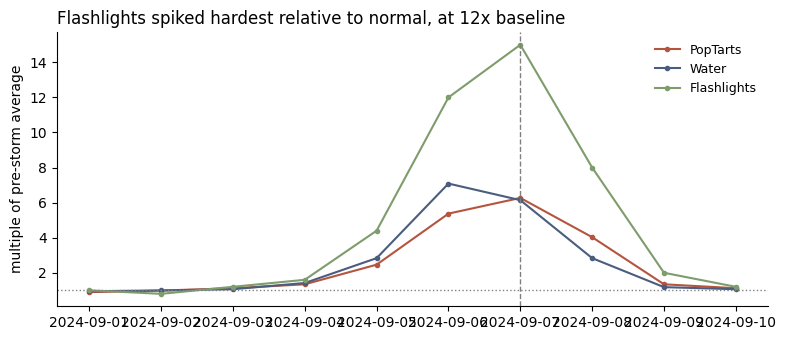

Flashlights    15.0
Water           7.1
PopTarts        6.3
dtype: float64


In [16]:
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()
indexed = daily / baseline

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(indexed.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.set_title('Flashlights spiked hardest relative to normal, at 12x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(indexed.max().round(1).sort_values(ascending=False))

Two charts, same data, different findings. The raw chart says water is the story; the indexed chart says flashlights are. Both belong in the presentation, in that order.

**TODO:** index your own products to their baseline and see whether your ranking changes.

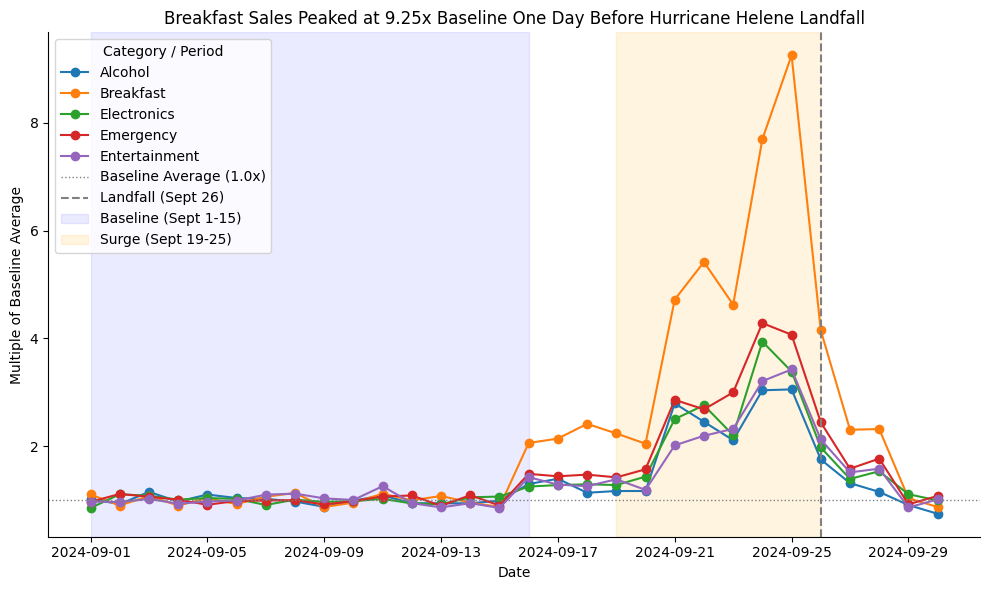

category
Breakfast        9.25
Emergency        4.28
Electronics      3.94
Entertainment    3.43
Alcohol          3.06
dtype: float64


In [17]:
# Q1, Step 7: Compare Daily Sales Relative to Baseline

# Pivot daily sales into wide format
daily_wide = top_daily_sales.pivot(
    index='date',
    columns='category',
    values='units_sold'
)

baseline_avg = daily_wide.loc['2024-09-01':'2024-09-15'].mean()

# Select the top five categories and index their daily sales
# indexed sales = daily units sold / baseline average
indexed = daily_wide / baseline_avg

# Create the line chart for relative daily sales
fig, ax = plt.subplots(figsize=(10, 6))

for category in indexed.columns:
    ax.plot(indexed.index, indexed[category],
            marker='o', label=category)

ax.axhline(1.0, color='gray', linestyle=':', linewidth=1,
           label='Baseline Average (1.0x)')

ax.axvline(pd.Timestamp('2024-09-26'), color='gray',
           linestyle='--', linewidth=1.5,
           label='Landfall (Sept 26)')

# Highlight baseline period: September 1–15
ax.axvspan(
    pd.Timestamp('2024-09-01'),
    pd.Timestamp('2024-09-16'),
    color='blue',
    alpha=0.08,
    label='Baseline (Sept 1-15)'
)

# Highlight surge period: September 19–25
ax.axvspan(
    pd.Timestamp('2024-09-19'),
    pd.Timestamp('2024-09-26'),
    color='orange',
    alpha=0.12,
    label='Surge (Sept 19-25)'
)

ax.set_title('Breakfast Sales Peaked at 9.25x Baseline One Day Before Hurricane Helene Landfall')
ax.set_xlabel('Date')
ax.set_ylabel('Multiple of Baseline Average')
ax.set_xticks(pd.date_range('2024-09-01', '2024-09-30', freq='4D'))

for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)

ax.legend(title='Category / Period')
plt.tight_layout()
plt.show()

# Identify the peak sales multiple for each category (highest daily sales / baseline average)
print(indexed.max().round(2).sort_values(ascending=False))


### Pattern 3 — before-and-after for Q2

The SKU consolidation question needs a comparison, not a description. Show the number somebody would have reported without your work next to the number with it.

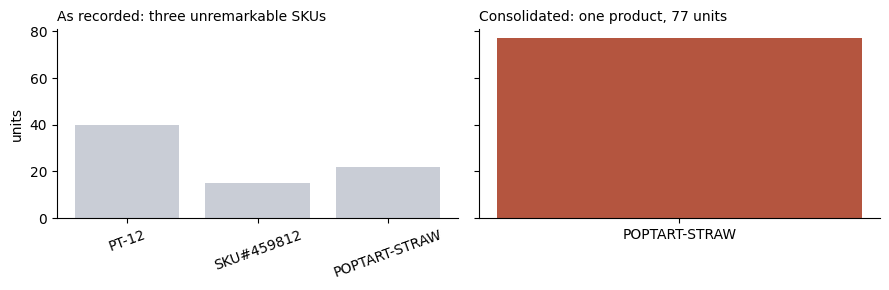

In [18]:
fragmented = pd.Series({'PT-12': 40, 'SKU#459812': 15, 'POPTART-STRAW': 22})
consolidated = pd.Series({'POPTART-STRAW': 77})

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title('As recorded: three unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title('Consolidated: one product, 77 units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** build this for your largest consolidated product family. State the multiple.

In [19]:
# Q2, Step 1: Calculate units sold for Pop-Tart after SKU consolidation
poptarts_after = clean_transactions[clean_transactions['sku'] == 'POPTART-STRAW']

poptart_sales_after = (
    poptarts_after.dropna(subset=['date'])
    .groupby(['sku'])['quantity']
    .sum()
    .reset_index(name='units_sold')
)

poptart_sales_after

,sku,units_sold
0,POPTART-STRAW,5005


In [20]:
# Q2, Step 2: Identify original Pop-Tart SKU variants
poptarts_before = transactions[transactions['product_name'].str.lower().str.contains('pop')].copy()

# Drop duplicates
poptarts_before = poptarts_before.drop_duplicates()

# Normalize timestamps
poptarts_before['timestamp'] = pd.to_datetime(poptarts_before['timestamp'], errors='coerce', format='mixed')

# Create date column
poptarts_before['date'] = poptarts_before['timestamp'].dt.normalize()


# Convert quantity to numeric
poptarts_before['quantity'] = pd.to_numeric(poptarts_before['quantity'], errors='coerce')
# Remove missing and negative quantities
poptarts_before = poptarts_before.dropna(subset=['quantity'])
poptarts_before = poptarts_before[poptarts_before['quantity'] > 0]

# Remove missing dates
poptarts_before = poptarts_before.dropna(subset=['date'])

# Inspect original SKUs
grouped_poptart_sku = poptarts_before.groupby('sku')['product_name'].first()    # one representative product name for each SKU
display(grouped_poptart_sku)
display(poptarts_before[['sku', 'product_name', 'quantity']].head())

,product_name
sku,
POPTART-STRAW,Strawberry Pop-Tart
PT-12,Pop Tarts - Strawberry
PT_STRAWBERRY,pop-tarts strawberry
SKU#459812,POPTART-STRAWBERRY


,sku,product_name,quantity
21,PT_STRAWBERRY,pop-tarts strawberry,4
27,SKU#459812,POPTART-STRAWBERRY,4
29,PT_STRAWBERRY,Strawberry Pop-Tart,3
47,PT-12,Pop Tarts - Strawberry,3
52,POPTART-STRAW,Strawberry Pop-Tart,1


In [21]:
# Q2, Step 3: Calculate total units sold before SKU consolidation
poptart_sales_before = (
    poptarts_before.groupby(['sku'])['quantity'].sum()
    .reset_index(name='units_sold')
)
poptart_sales_before

,sku,units_sold
0,POPTART-STRAW,1239
1,PT-12,1332
2,PT_STRAWBERRY,1230
3,SKU#459812,1204


In [22]:
# Q2, Step 4: Verify total units sold before and after
print("Before:", poptart_sales_before['units_sold'].sum())
print("After:", poptart_sales_after['units_sold'].sum())

Before: 5005
After: 5005


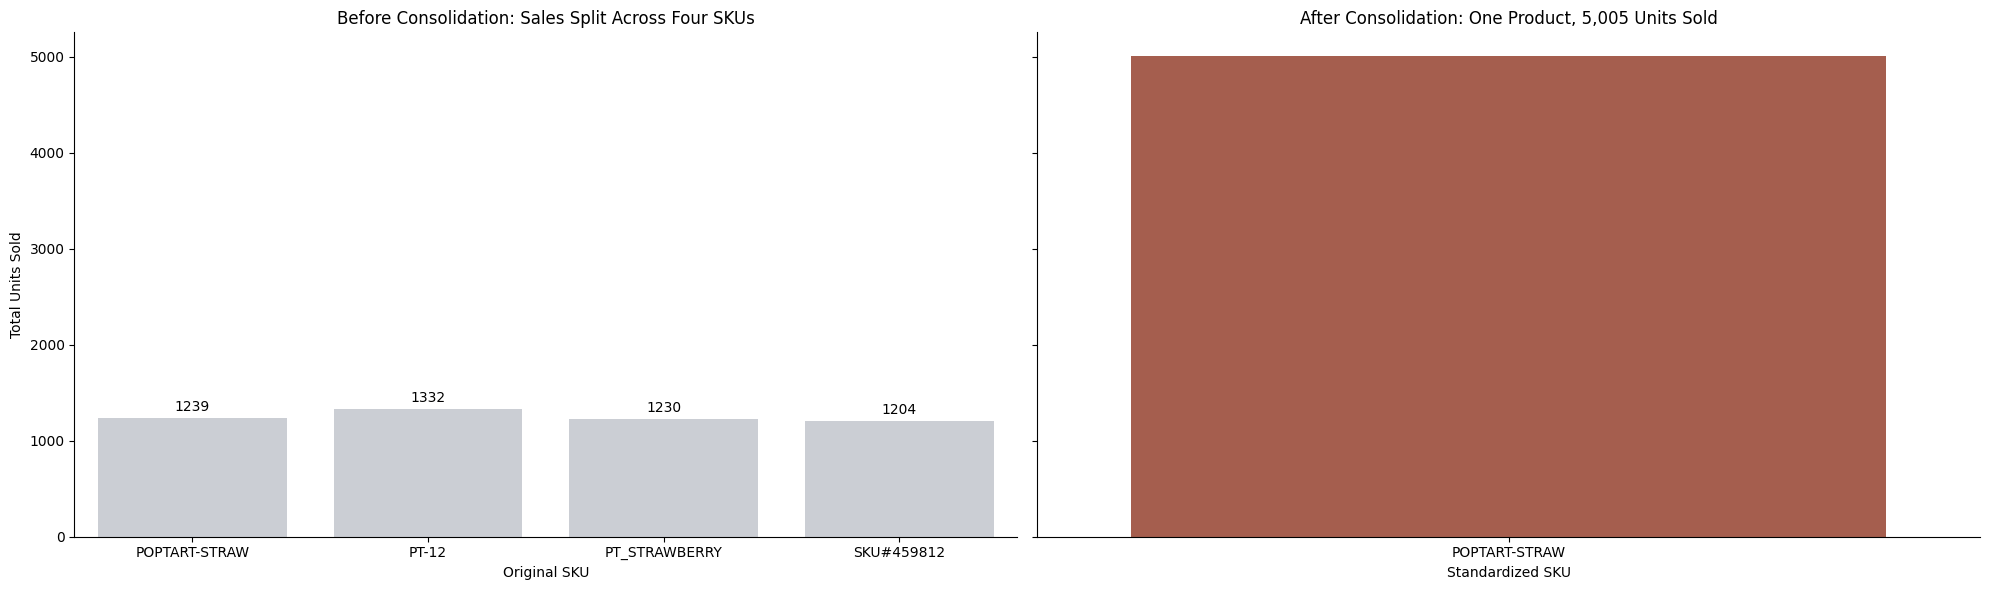

In [23]:
# Q2, Step 5: Create a side-by-side bar charts
fig, axes = plt.subplots(ncols=2, figsize=(20,6), sharey=True)

# Before SKU consolidation
sns.barplot(data=poptart_sales_before, x='sku', y='units_sold', color='#c9cdd6', ax=axes[0])
axes[0].set_title('Before Consolidation: Sales Split Across Four SKUs')
axes[0].set_xlabel('Original SKU')
axes[0].set_ylabel('Total Units Sold')
axes[0].bar_label(axes[0].containers[0], fmt='%.0f', padding=3)

# After SKU consolidation
sns.barplot(data=poptart_sales_after, x='sku', y='units_sold', color='#b4553f', ax=axes[1])
axes[1].set_title('After Consolidation: One Product, 5,005 Units Sold')
axes[1].set_xlabel('Standardized SKU')

for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


### Pattern 4 — Q4, stores by distance

Aggregate by store, join whatever geography you have, and look for the gradient. Watch the group sizes — a store with four transactions will produce a wild average.

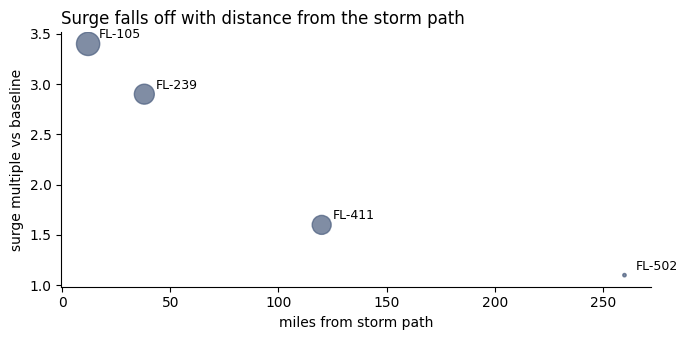

note the smallest bubble: FL-502 has only 90 transactions,
so its 1.1x is barely distinguishable from noise.


In [24]:
by_store = pd.DataFrame({
    'store_id': ['FL-105', 'FL-239', 'FL-411', 'FL-502'],
    'surge_multiple': [3.4, 2.9, 1.6, 1.1],
    'miles_from_path': [12, 38, 120, 260],
    'transactions': [4200, 3100, 2800, 90],
})

fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['transactions'] / 15
ax.scatter(by_store['miles_from_path'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge falls off with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm path')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('note the smallest bubble: FL-502 has only 90 transactions,')
print('so its 1.1x is barely distinguishable from noise.')

Sizing the points by transaction count is doing real work here — it tells the reader which points to trust. A four-point scatter is not a trend line, and you should say so out loud rather than fitting one.

**TODO:** build your version. If you only have a handful of stores, present it as a table with a comment instead of a scatter — a chart with five points and a regression line will get asked about.

In [25]:
# TODO

### Before you leave

- At least two presentation-ready charts, each with a message title
- Q1 has a stated baseline window and a multiple
- Q2 has a before-and-after comparison
- Everything pushed

Monday is presentations. The timing breakdown and the self-check are in Monday's notebook — read it tonight, not Monday morning.

---

## Checkpoint (participation)

Report the surge multiple you found for your top product and the baseline window you used to get it.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [26]:
# Checkpoint
top_product = 'Breakfast'         # TODO: your biggest mover
surge_multiple = 5.14        # TODO: how many times baseline: 376.86 / 73.27
baseline_window = 'Sept 1-15 (15 days)'     # TODO: e.g. '14 days before Sept 4'
charts_ready = 4          # TODO: how many presentation-ready charts you have

print('top product:', top_product)
print('surge multiple:', surge_multiple)
print('baseline window:', baseline_window)
print('charts ready:', charts_ready)

top product: Breakfast
surge multiple: 5.14
baseline window: Sept 1-15 (15 days)
charts ready: 4
